In [1]:
# 라이브러리
import os
import pandas as pd
from sqlalchemy import create_engine
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from scipy.stats import pearsonr, spearmanr, pointbiserialr
import statsmodels.api as sm

# 그래프 기본 설정
sns.set()
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['figure.figsize'] = 12, 6
plt.rcParams['font.size'] = 14
plt.rcParams['axes.unicode_minus'] = False

# 모든 컬럼 출력 설정
pd.set_option('display.max_rows', 100)       # 최대 행 수
pd.set_option('display.max_colwidth', None)  # 컬럼 내 값 길이 제한 해제

In [2]:
# MySQL 접속 설정
username = "root"      # MySQL 사용자명
password = "1234"      # MySQL 비밀번호
host = "127.0.0.1"     # 로컬호스트
port = 3306            # 포트
database = "ott_db"  # DB 이름

# MySQL 엔진 생성
engine = create_engine(f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}")

In [3]:
query = """
SELECT 
    c.*,           -- contents 테이블의 전체 컬럼
    u.nation,   -- user 테이블에서 필요한 컬럼만 명시
    u.gender,
    u.age
FROM contents AS c
JOIN user AS u
ON c.user_id = u.user_id
"""
df_contents = pd.read_sql(query, engine)
df_contents

,user_id,frequency_series,frequency_movie,frequency_variety,genre_series_movie_rom_2022,genre_series_movie_rom_2023,genre_series_movie_fant_2022,genre_series_movie_fant_2023,genre_series_movie_action_2022,genre_series_movie_action_2023,...,viewed_movie,viewed_variety,viewed_music,viewed_animation,viewed_webtoon,viewed_webnovel,viewed_game,nation,gender,age
0,20228,1주일에 3~4일,1주일에 3~4일,이용안함,0.0,NaN,0.0,NaN,1.0,NaN,...,1,0,0,0,0,0,0,미국,여성,40-44세
1,202211,1주일에 3~4일,1주일에 3~4일,1주일에 1~2일,1.0,NaN,0.0,NaN,1.0,NaN,...,1,1,1,0,0,0,0,미국,남성,25-29세
2,202212,매일,1주일에 3~4일,매일,1.0,NaN,0.0,NaN,0.0,NaN,...,1,1,1,1,0,0,0,미국,여성,20-24세
3,202213,1주일에 1~2일,1주일에 1~2일,2~3달에 1~2일 이하,1.0,NaN,1.0,NaN,1.0,NaN,...,1,1,0,0,0,0,0,미국,여성,45-49세
4,202215,1주일에 3~4일,1주일에 1~2일,1주일에 5~6일,1.0,NaN,0.0,NaN,1.0,NaN,...,1,1,1,1,1,1,1,미국,여성,25-29세
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10857,202310296,한 달에 1~3일,한 달에 1~3일,이용안함,NaN,0.0,NaN,1.0,NaN,1.0,...,1,0,0,1,0,0,0,일본,여성,25-29세
10858,202310298,매일,매일,매일,NaN,0.0,NaN,1.0,NaN,0.0,...,1,1,1,1,1,1,0,일본,여성,15-19세
10859,202310300,매일,1주일에 5~6일,1주일에 5~6일,NaN,1.0,NaN,1.0,NaN,0.0,...,1,1,1,1,1,1,0,일본,남성,50-54세
10860,202310301,1주일에 1~2일,1주일에 1~2일,이용안함,NaN,1.0,NaN,0.0,NaN,1.0,...,1,0,1,0,0,0,0,일본,남성,40-44세


### 🎯[가설 8] 시청 방식(추천 vs 검색 vs 오리지널 클릭)은 국가별로 유의미한 차이를 보인다.

- 귀무가설(H0): 국가별로 콘텐츠 접근 방식 분포에 차이가 없다.
- 대립가설(H1): 국가별로 콘텐츠 접근 방식 분포에 차이가 있다.

📊 Chi-square: 28.567811170532615
p-value: 0.0045652414106605345
✅ 유의미한 차이 있음 → 국가별 콘텐츠 접근 방식이 다름


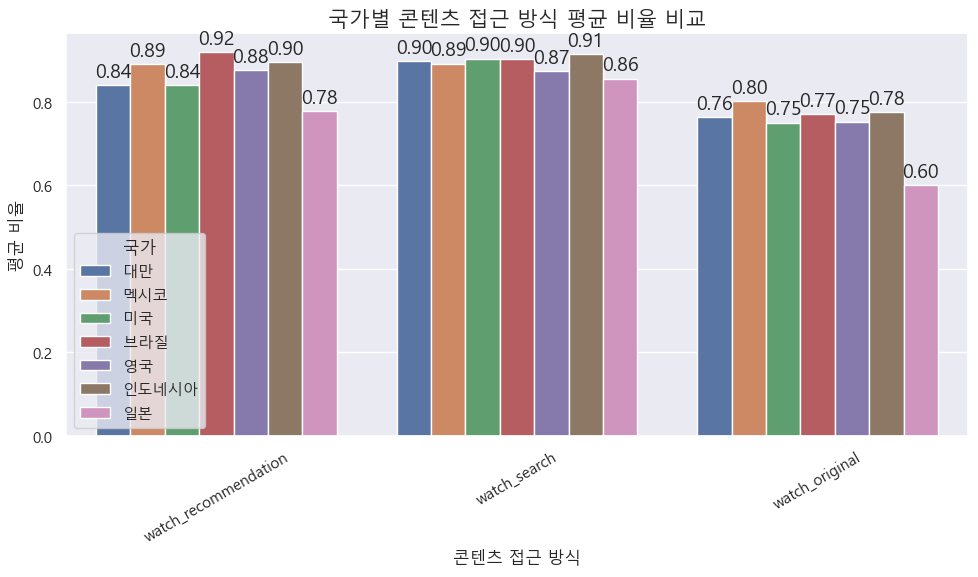

In [4]:
# 🎯 1. 콘텐츠 접근 방식 변수
access_cols = [
    "watch_recommendation",  # 추천 기반
    "watch_search",          # 검색 기반
    "watch_original"         # 오리지널 클릭
]

# 🎯 2. 국가별 합계 → 카이제곱 검정용 교차표
access_sum = df_contents.groupby("nation")[access_cols].sum()

# 카이제곱 검정
chi2, p, dof, expected = chi2_contingency(access_sum)
print("📊 Chi-square:", chi2)
print("p-value:", p)

if p < 0.05:
    print("✅ 유의미한 차이 있음 → 국가별 콘텐츠 접근 방식이 다름")
else:
    print("❌ 유의미한 차이 없음 → 국가별 콘텐츠 접근 방식이 비슷함")

# 🎯 3. 국가별 평균 비율 (응답자 수 차이 보정)
access_mean = df_contents.groupby("nation")[access_cols].mean().reset_index()

# melt → long format
access_melted = access_mean.melt(
    id_vars="nation",
    value_vars=access_cols,
    var_name="콘텐츠 접근 방식",
    value_name="비율"
)

# 🎯 4. 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=access_melted,
    x="콘텐츠 접근 방식", y="비율", hue="nation"
)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", label_type="edge", padding=3)
plt.title("국가별 콘텐츠 접근 방식 평균 비율 비교", fontsize=15)
plt.ylabel("평균 비율")
plt.xticks(rotation=30)
plt.legend(title="국가")
plt.tight_layout()
plt.show()

In [5]:
# 전략 대상 국가만 필터링
target_nations = ["인도네시아", "미국", "대만"]
df_target = df_contents[df_contents["nation"].isin(target_nations)]

# 교차표 생성 (합계)
access_sum_target = df_target.groupby("nation")[access_cols].sum()

# 카이제곱 검정
chi2, p, dof, expected = chi2_contingency(access_sum_target)
print("📊 Chi-square:", chi2)
print("p-value:", p)

if p < 0.05:
    print("✅ 유의미한 차이 있음 → 전략 대상 국가 간 콘텐츠 접근 방식이 다름")
else:
    print("❌ 유의미한 차이 없음 → 전략 대상 국가 간 콘텐츠 접근 방식이 비슷함")

📊 Chi-square: 1.365697231451415
p-value: 0.8501345451379707
❌ 유의미한 차이 없음 → 전략 대상 국가 간 콘텐츠 접근 방식이 비슷함


### 🎯[가설 9] 콘텐츠 이용 빈도가 높은 사용자일수록 K-콘텐츠에 대한 노출 및 관심이 높다.

In [6]:
# 1) df_contents (콘텐츠 장르별 이용 빈도)
df_contents = df_contents[['user_id', 'frequency_series', 'frequency_movie', 'frequency_variety']]

# 2) ott 테이블 (OTT 전체 이용 빈도)
ott = pd.read_sql("SELECT user_id, frequency FROM ott", engine)

# 3) kcontents 테이블 (K-콘텐츠 이용 여부)
kcontents = pd.read_sql("SELECT * FROM kcontents", engine)

# K-콘텐츠 이용 여부 계산
k_cols = [
    'content_type_drama', 'content_type_movie', 'content_type_variety',
    'content_type_music', 'content_type_kpop', 'content_type_animation',
    'content_type_webtoon', 'content_type_webnovel', 'content_type_esport'
]

# 하나라도 1이면 이용(1), 아니면 0
kcontents['k_content_use'] = kcontents[k_cols].apply(lambda row: 1 if (row == 1).any() else 0, axis=1)

# 4) 테이블 병합
df_merge = df_contents.merge(ott[['user_id', 'frequency']], on='user_id', how='left') \
                      .merge(kcontents[['user_id', 'k_content_use']], on='user_id', how='left')


In [7]:
# K-콘텐츠 이용자 수
num_k_users = (df_merge['k_content_use'] == 1).sum()
print(f"K-콘텐츠 이용자 수: {num_k_users:,}명")

# 비율까지 보고 싶으면
total_users = df_merge['user_id'].nunique()
ratio_k_users = num_k_users / total_users * 100
print(f"전체 대비 비율: {ratio_k_users:.2f}%")

K-콘텐츠 이용자 수: 6,685명
전체 대비 비율: 61.54%


In [8]:
# 매핑 딕셔너리 (이용안함 추가)
freq_map = {
    "매일": 7,
    "1주일에 5~6일": 5.5,
    "1주일에 3~4일": 3.5,
    "1주일에 1~2일": 1.5,
    "한 달에 1~3일": 0.5,
    "2~3달에 1~2일 이하": 0.2,
    "이용안함": 0
}

freq_map_ott = {
    "매일": 7.0,
    "1주일에 5~6일": 5.5,
    "1주일에 3~4일": 3.5,
    "1주일에 1~2일": 1.5,
    "한 달에 1일": 0.5,       
    "2~3달에 1일 이하": 0.2     
}

# 1) 문자열 정리 + 매핑 적용
content_freq_cols = ['frequency_series', 'frequency_movie', 'frequency_variety']

# 콘텐츠별 빈도 → freq_map
for col in content_freq_cols:
    s = df_merge[col]
    # NaN은 그대로 두고, 값이 있으면 strip 후 매핑
    s_clean = s.where(s.isna(), s.astype(str).str.strip())
    df_merge[col] = s_clean.map(freq_map)

# OTT 전체 빈도 → freq_map_ott
s = df_merge['frequency']
s_clean = s.where(s.isna(), s.astype(str).str.strip())
df_merge['frequency'] = s_clean.map(freq_map_ott)

# 2) 변환 결과 확인
print(df_merge[['frequency_series','frequency_movie','frequency_variety','frequency']].head())

# 3) 값 분포(누락 체크)
print("\n[분포 확인]")
for col in ['frequency_series','frequency_movie','frequency_variety','frequency']:
    vc = df_merge[col].value_counts(dropna=False).sort_index()
    print(f"{col}:\n{vc}\n")

   frequency_series  frequency_movie  frequency_variety  frequency
0               3.5              3.5                0.0        3.5
1               3.5              3.5                1.5        3.5
2               7.0              3.5                7.0        7.0
3               1.5              1.5                0.2        7.0
4               3.5              1.5                5.5        3.5

[분포 확인]
frequency_series:
frequency_series
0.0    1538
0.2     265
0.5     544
1.5    1887
3.5    2299
5.5    1740
7.0    2589
Name: count, dtype: int64

frequency_movie:
frequency_movie
0.0     876
0.2     331
0.5    1090
1.5    3060
3.5    2224
5.5    1483
7.0    1798
Name: count, dtype: int64

frequency_variety:
frequency_variety
0.0    4199
0.2     358
0.5     687
1.5    1679
3.5    1575
5.5    1119
7.0    1245
Name: count, dtype: int64

frequency:
frequency
0.2     119
0.5     322
1.5     980
3.5    2104
5.5    2379
7.0    4958
Name: count, dtype: int64



In [9]:
df_merge['frequency'].value_counts(dropna=False).sort_index()

frequency
0.2     119
0.5     322
1.5     980
3.5    2104
5.5    2379
7.0    4958
Name: count, dtype: int64

In [10]:
# 0) K-콘텐츠 이용 여부 NaN → 0, int 변환
df_merge['k_content_use'] = df_merge['k_content_use'].fillna(0).astype(int)

# 1) 분석 대상 컬럼
usage_vars = ['frequency_series', 'frequency_movie', 'frequency_variety', 'frequency']  # OTT 전체 빈도 포함
y = df_merge['k_content_use']

print("=== 상관분석 (Pearson / Spearman / Point-biserial) ===")

for col in usage_vars:
    x = df_merge[col].astype(float)  # 이미 숫자형이므로 바로 변환

    # 유효 표본 필터링
    mask = x.notna() & y.notna()
    x_valid = x[mask]
    y_valid = y[mask]

    if len(x_valid) < 3:
        print(f"[{col}] 유효 표본이 너무 적습니다 (n={len(x_valid)}).")
        continue

    # Pearson
    pr, pr_p = pearsonr(x_valid, y_valid)

    # Spearman
    sr, sr_p = spearmanr(x_valid, y_valid)

    # Point-biserial
    pbr, pbr_p = pointbiserialr(x_valid, y_valid)

    print(f"\n[{col}] n={len(x_valid)}")
    print(f"  • Pearson r      = {pr:.3f}  (p={pr_p:.4g})")
    print(f"  • Spearman ρ     = {sr:.3f}  (p={sr_p:.4g})")
    print(f"  • Point-biserial = {pbr:.3f}  (p={pbr_p:.4g})")


=== 상관분석 (Pearson / Spearman / Point-biserial) ===

[frequency_series] n=10862
  • Pearson r      = 0.170  (p=4.252e-71)
  • Spearman ρ     = 0.173  (p=6.659e-74)
  • Point-biserial = 0.170  (p=4.252e-71)

[frequency_movie] n=10862
  • Pearson r      = 0.092  (p=6.532e-22)
  • Spearman ρ     = 0.106  (p=1.649e-28)
  • Point-biserial = 0.092  (p=6.532e-22)

[frequency_variety] n=10862
  • Pearson r      = 0.080  (p=9.64e-17)
  • Spearman ρ     = 0.091  (p=1.48e-21)
  • Point-biserial = 0.080  (p=9.64e-17)

[frequency] n=10862
  • Pearson r      = 0.104  (p=1.368e-27)
  • Spearman ρ     = 0.096  (p=1.775e-23)
  • Point-biserial = 0.104  (p=1.368e-27)


In [11]:
# 1) 분석 대상 컬럼
usage_vars = ['frequency_series', 'frequency_movie', 'frequency_variety', 'frequency']  # 독립변수
X = df_merge[usage_vars].astype(float)
y = df_merge['k_content_use'].astype(int)

# 2) 결측 제거
mask = X.notna().all(axis=1) & y.notna()
X = X[mask]
y = y[mask]

# 3) 상수항 추가
X = sm.add_constant(X)

# 4) 로지스틱 회귀 모델 적합
logit_model = sm.Logit(y, X)
result = logit_model.fit()

# 5) 결과 출력
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.650206
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          k_content_use   No. Observations:                10862
Model:                          Logit   Df Residuals:                    10857
Method:                           MLE   Df Model:                            4
Date:                Tue, 12 Aug 2025   Pseudo R-squ.:                 0.02408
Time:                        13:41:03   Log-Likelihood:                -7062.5
converged:                       True   LL-Null:                       -7236.8
Covariance Type:            nonrobust   LLR p-value:                 3.701e-74
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.1950      0.054     -3.589      0.000      -0.301      -0.089
frequenc

In [12]:
odds_ratios = pd.DataFrame({
    "변수": X.columns,
    "회귀계수": result.params,
    "오즈비(OR)": np.exp(result.params),
    "p값": result.pvalues
})
print(odds_ratios)

                                  변수      회귀계수   오즈비(OR)            p값
const                          const -0.195011  0.822825  3.314387e-04
frequency_series    frequency_series  0.115525  1.122462  2.045545e-39
frequency_movie      frequency_movie  0.028418  1.028825  2.505192e-03
frequency_variety  frequency_variety  0.020721  1.020937  1.852118e-02
frequency                  frequency  0.025884  1.026222  1.885601e-02


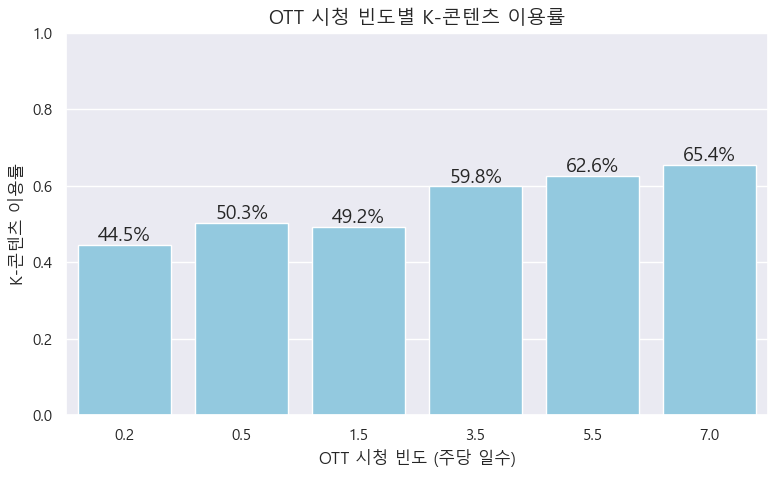

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 빈도 값 순서 정의
freq_order = [0.2, 0.5, 1.5, 3.5, 5.5, 7.0]

# 이용률 계산
freq_k_ratio = (
    df_merge.groupby('frequency')['k_content_use']
    .mean()
    .reindex(freq_order)  # 순서 고정
    .reset_index()
)

# 시각화
plt.figure(figsize=(8,5))
sns.barplot(data=freq_k_ratio, x='frequency', y='k_content_use', order=freq_order, color='skyblue')

# 퍼센트 라벨 표시
for idx, row in freq_k_ratio.iterrows():
    if pd.notna(row['k_content_use']):
        plt.text(
            x=idx, 
            y=row['k_content_use'] + 0.01, 
            s=f"{row['k_content_use']*100:.1f}%", 
            ha='center'
        )

plt.title("OTT 시청 빈도별 K-콘텐츠 이용률", fontsize=14)
plt.xlabel("OTT 시청 빈도 (주당 일수)")
plt.ylabel("K-콘텐츠 이용률")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [14]:
# 1) df_contents (콘텐츠 장르별 이용 빈도)
df_contents = df_contents[['user_id', 'frequency_series', 'frequency_movie', 'frequency_variety']]

# 2) ott 테이블 (OTT 전체 이용 빈도)
ott = pd.read_sql("SELECT user_id, frequency FROM ott", engine)

# 3) kcontents 테이블 (K-콘텐츠 이용 여부)
kcontents = pd.read_sql("SELECT * FROM kcontents", engine)

# K-콘텐츠 이용 여부 계산
k_cols = [
    'content_type_drama', 'content_type_movie', 'content_type_variety',
    'content_type_music', 'content_type_kpop', 'content_type_animation',
    'content_type_webtoon', 'content_type_webnovel', 'content_type_esport'
]

# 하나라도 1이면 이용(1), 아니면 0
kcontents['k_content_use'] = kcontents[k_cols].apply(lambda row: 1 if (row == 1).any() else 0, axis=1)

# 4) 테이블 병합
df_merge = df_contents.merge(ott[['user_id', 'frequency']], on='user_id', how='left') \
                      .merge(kcontents[['user_id', 'k_content_use']], on='user_id', how='left')

In [15]:
# 크래머 V 계산 함수
def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2_corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    r_corr = r - ((r-1)**2)/(n-1)
    k_corr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2_corr / min((k_corr-1), (r_corr-1)))

# 분석 대상 변수
categorical_vars = ['frequency_series', 'frequency_movie', 'frequency_variety', 'frequency']

results = []
for col in categorical_vars:
    # 교차표
    contingency = pd.crosstab(df_merge[col], df_merge['k_content_use'])
    
    # 카이제곱 검정
    chi2, p, dof, expected = chi2_contingency(contingency)
    
    # 크래머 V
    cv = cramers_v(contingency)
    
    results.append({
        '변수': col,
        '카이제곱 χ²': round(chi2, 3),
        '자유도': dof,
        'p값': p,
        '크래머 V': round(cv, 3)
    })

# 결과 DataFrame
chi_cramer_df = pd.DataFrame(results)
print(chi_cramer_df)

                  변수  카이제곱 χ²  자유도            p값  크래머 V
0   frequency_series  440.788    6  4.714410e-92  0.200
1    frequency_movie  191.228    6  1.394359e-38  0.131
2  frequency_variety  109.747    6  2.303057e-21  0.098
3          frequency  129.454    5  3.108367e-26  0.107


In [16]:
query = """
SELECT 
    c.*,           -- contents 테이블의 전체 컬럼
    u.nation,   -- user 테이블에서 필요한 컬럼만 명시
    u.gender,
    u.age
FROM contents AS c
JOIN user AS u
ON c.user_id = u.user_id
"""
df_contents = pd.read_sql(query, engine)
df_contents

,user_id,frequency_series,frequency_movie,frequency_variety,genre_series_movie_rom_2022,genre_series_movie_rom_2023,genre_series_movie_fant_2022,genre_series_movie_fant_2023,genre_series_movie_action_2022,genre_series_movie_action_2023,...,viewed_movie,viewed_variety,viewed_music,viewed_animation,viewed_webtoon,viewed_webnovel,viewed_game,nation,gender,age
0,20228,1주일에 3~4일,1주일에 3~4일,이용안함,0.0,NaN,0.0,NaN,1.0,NaN,...,1,0,0,0,0,0,0,미국,여성,40-44세
1,202211,1주일에 3~4일,1주일에 3~4일,1주일에 1~2일,1.0,NaN,0.0,NaN,1.0,NaN,...,1,1,1,0,0,0,0,미국,남성,25-29세
2,202212,매일,1주일에 3~4일,매일,1.0,NaN,0.0,NaN,0.0,NaN,...,1,1,1,1,0,0,0,미국,여성,20-24세
3,202213,1주일에 1~2일,1주일에 1~2일,2~3달에 1~2일 이하,1.0,NaN,1.0,NaN,1.0,NaN,...,1,1,0,0,0,0,0,미국,여성,45-49세
4,202215,1주일에 3~4일,1주일에 1~2일,1주일에 5~6일,1.0,NaN,0.0,NaN,1.0,NaN,...,1,1,1,1,1,1,1,미국,여성,25-29세
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10857,202310296,한 달에 1~3일,한 달에 1~3일,이용안함,NaN,0.0,NaN,1.0,NaN,1.0,...,1,0,0,1,0,0,0,일본,여성,25-29세
10858,202310298,매일,매일,매일,NaN,0.0,NaN,1.0,NaN,0.0,...,1,1,1,1,1,1,0,일본,여성,15-19세
10859,202310300,매일,1주일에 5~6일,1주일에 5~6일,NaN,1.0,NaN,1.0,NaN,0.0,...,1,1,1,1,1,1,0,일본,남성,50-54세
10860,202310301,1주일에 1~2일,1주일에 1~2일,이용안함,NaN,1.0,NaN,0.0,NaN,1.0,...,1,0,1,0,0,0,0,일본,남성,40-44세


In [17]:
# 1. 2022 데이터만 필터링 (user_id가 '2023'으로 시작하지 않는 행)
df_2022 = df_contents[~df_contents['user_id'].astype(str).str.startswith('2023')].copy()

# 2. 확인
print(df_2022.shape)
print(df_2022['user_id'].head())

(4536, 77)
0     20228
1    202211
2    202212
3    202213
4    202215
Name: user_id, dtype: int64


In [18]:
df_2022 = df_contents[~df_contents['user_id'].astype(str).str.startswith('2023')].copy()

# K-콘텐츠 선호도 DF도 2022 데이터만
df_k2022 = kcontents[~kcontents['user_id'].astype(str).str.startswith('2023')].copy()

# user_id 기준 병합
df_2022 = df_2022.merge(
    df_k2022[['user_id', 'drama_movie_genre_rank1', 'drama_movie_genre_rank2',
              'variety_favorite_rank1', 'variety_favorite_rank2']],
    on='user_id',
    how='left'
)

In [19]:
df_2022.columns

Index(['user_id', 'frequency_series', 'frequency_movie', 'frequency_variety',
       'genre_series_movie_rom_2022', 'genre_series_movie_rom_2023',
       'genre_series_movie_fant_2022', 'genre_series_movie_fant_2023',
       'genre_series_movie_action_2022', 'genre_series_movie_action_2023',
       'genre_series_movie_horr_2022', 'genre_series_movie_horr_2023',
       'genre_series_movie_comedy_2023', 'genre_series_movie_history_2022',
       'genre_series_movie_history_2023', 'genre_series_movie_human_2022',
       'genre_series_movie_human_2023', 'genre_series_movie_docu_2022',
       'genre_series_movie_docu_2023', 'genre_series_movie_musical_2022',
       'genre_series_movie_musical_2023', 'genre_series_movie_ani_2023',
       'genre_series_movie_kids_2023', 'genre_series_movie_teleno_2023',
       'genre_series_movie_etc_2022', 'genre_series_movie_etc_2023',
       'genre_variety_game_2022', 'genre_variety_game_2023',
       'genre_variety_travel_2022', 'genre_variety_travel_2023'

In [20]:
# NaN이 나온 변수 목록
nan_vars = [
    'genre_series_movie_human_2022',
    'genre_variety_etc_2022'
]

# 각 변수별로 값 분포 확인
for col in nan_vars:
    print(f"\n[{col}] 값 분포")
    print(df_2022[col].value_counts(dropna=False))


[genre_series_movie_human_2022] 값 분포
genre_series_movie_human_2022
0.0    2764
1.0    1772
Name: count, dtype: int64

[genre_variety_etc_2022] 값 분포
genre_variety_etc_2022
0.0    4095
1.0     441
Name: count, dtype: int64


In [21]:
df_2022['drama_movie_genre_rank1'].unique()
df_2022['drama_movie_genre_rank2'].unique()

array(['이용하지 않음', '액션', '역사물', '기타', 'SF/판타지', '로맨스/멜로', '휴면/가족',
       '공포/스릴러/좀비물', '뮤지컬', '다큐멘터리'], dtype=object)

In [22]:
# -*- coding: utf-8 -*-
import re
import math
import warnings
from statsmodels.tools.sm_exceptions import PerfectSeparationError, ConvergenceWarning

# ========================
# 0) 랭크 컬럼 문자열 정리 + 오타 교정 (드라마/영화 vs 예능 분리)
# ========================
rank_cols_drama = ['drama_movie_genre_rank1', 'drama_movie_genre_rank2']
rank_cols_var   = ['variety_favorite_rank1', 'variety_favorite_rank2']

def clean_text(s):
    if pd.isna(s):
        return s
    s = str(s)
    s = s.replace('\u3000', ' ')         # 전각 공백 → 일반 공백
    s = s.strip()
    s = re.sub(r'[<>]', '', s)           # 꺽쇠 제거
    s = re.sub(r'\s+', ' ', s)           # 여러 공백 → 하나
    return s

# 0-1) 공통 클린
for c in rank_cols_drama + rank_cols_var:
    if c in df_2022.columns:
        df_2022[c] = df_2022[c].apply(clean_text)

# 0-2) 드라마/영화 쪽만: 오타/불필요 괄호 정리
# - '휴면/가족' → '휴먼/가족'
# - '기타(예능)', '기타(영화)' 같은 변형 → '기타' 로 정규화
for c in rank_cols_drama:
    if c in df_2022.columns:
        df_2022[c] = (
            df_2022[c]
            .replace({'휴면/가족': '휴먼/가족'})
            .str.replace(r'기타\(.*?\)', '기타', regex=True)  # 괄호가 붙은 기타는 모두 '기타'
        )

# 0-3) 예능 쪽만: 오타 정리 + '기타' → '기타(예능)'
for c in rank_cols_var:
    if c in df_2022.columns:
        df_2022[c] = (
            df_2022[c]
            .replace({'휴면/가족': '휴먼/가족', '기타': '기타(예능)'})
            .str.replace(r'기타\(.*?\)', '기타(예능)', regex=True)  # 괄호 변형도 통일
        )

# ========================
# 1) 분석 대상 컬럼/장르명 매핑
# ========================
genre_map = {
    # 드라마/영화
    'genre_series_movie_rom_2022':      '로맨스/멜로',
    'genre_series_movie_fant_2022':     'SF/판타지',
    'genre_series_movie_action_2022':   '액션',
    'genre_series_movie_horr_2022':     '공포/스릴러/좀비물',
    'genre_series_movie_history_2022':  '역사물',
    'genre_series_movie_human_2022':    '휴먼/가족',
    'genre_series_movie_docu_2022':     '다큐멘터리',
    'genre_series_movie_musical_2022':  '뮤지컬',
    'genre_series_movie_etc_2022':      '기타',
    # 예능
    'genre_variety_game_2022':          '게임 예능',
    'genre_variety_travel_2022':        '여행 예능',
    'genre_variety_observe_2022':       '관찰 예능',
    'genre_variety_reality_2022':       '연애 리얼리티 예능',
    'genre_variety_survival_2022':      '오디션/서바이벌 예능',
    'genre_variety_culture_2022':       '교양 예능',
    'genre_variety_etc_2022':           '기타(예능)'
}
movie_genre_names = {'로맨스/멜로','SF/판타지','액션','공포/스릴러/좀비물','역사물','휴먼/가족','다큐멘터리','뮤지컬','기타'}
variety_genre_names = {'게임 예능','여행 예능','관찰 예능','연애 리얼리티 예능','오디션/서바이벌 예능','교양 예능','기타(예능)'}
genre_cols_2022 = list(genre_map.keys())

# ========================
# 2) 유틸: 크래머 V (안전 버전)
# ========================
def cramers_v_safe(ct):
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    denom = min(k - 1, r - 1)
    if n == 0 or denom <= 0:
        return np.nan, chi2
    phi2 = chi2 / n
    return math.sqrt(phi2 / denom), chi2

# ========================
# 3) 유틸: 로지스틱 회귀 (완전분리/수렴 실패 대비)
# ========================
def fit_logit_safe(y, X, var_name):
    res = {'회귀계수(β)': np.nan, '오즈비(OR)': np.nan, 'പ값': np.nan, 'n': len(y), 'note': ''}
    if y.nunique() < 2 or X[var_name].nunique() < 2:
        res['note'] = '단일값(분산=0)'
        return res
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    try:
        model = sm.Logit(y, X)
        result = model.fit(disp=0)
        beta = result.params[var_name]
        pval = result.pvalues[var_name]
        res.update({'회귀계수(β)': beta, '오즈비(OR)': float(np.exp(beta)), 'പ값': float(pval)})
        return res
    except (PerfectSeparationError, np.linalg.LinAlgError):
        try:
            result = sm.Logit(y, X).fit_regularized(method='l1', alpha=1.0, disp=0)
            beta = result.params[var_name]
            res.update({'회귀계수(β)': beta, '오즈비(OR)': float(np.exp(beta)), 'പ값': np.nan, 'note': 'regularized'})
            return res
        except Exception as e:
            res['note'] = f'fail:{type(e).__name__}'
            return res
    except Exception as e:
        res['note'] = f'fail:{type(e).__name__}'
        return res

# ========================
# 4) 선호 플래그 생성 함수
# ========================
def build_prefer_flag(df, genre_label):
    # 필요한 컬럼 없으면 생성
    for c in rank_cols_drama + rank_cols_var:
        if c not in df.columns:
            df[c] = np.nan

    if genre_label in movie_genre_names:
        prefer = df[rank_cols_drama].isin([genre_label]).any(axis=1)
    elif genre_label in variety_genre_names:
        prefer = df[rank_cols_var].isin([genre_label]).any(axis=1)
    else:
        prefer = pd.Series(False, index=df.index)
    return prefer.astype(int)

# ========================
# 5) 루프: 카이제곱/크래머V + 로지스틱
# ========================
chi_rows, logit_rows = [], []

for col in genre_cols_2022:
    genre_label = genre_map[col]

    watch = df_2022[col]                         # 0/1 시청 여부
    prefer = build_prefer_flag(df_2022, genre_label)  # 0/1 선호 여부

    mask = (~watch.isna()) & (~prefer.isna())
    w = watch[mask].astype(int)
    p = prefer[mask].astype(int)

    # --- 카이제곱 / 크래머 V ---
    if w.nunique() < 2 or p.nunique() < 2:
        chi_rows.append({'장르': genre_label, '변수': col,
                         '카이제곱 χ²': np.nan, '자유도': np.nan, 'p값': np.nan, '크래머 V': np.nan,
                         'n': int(mask.sum()), 'note': '한쪽 단일값'})
    else:
        ct = pd.crosstab(w, p)
        cramer_v, chi2 = cramers_v_safe(ct)
        dof = (ct.shape[0] - 1) * (ct.shape[1] - 1)
        pval = chi2_contingency(ct)[1]
        chi_rows.append({'장르': genre_label, '변수': col,
                         '카이제곱 χ²': chi2, '자유도': dof, 'p값': pval, '크래머 V': cramer_v,
                         'n': int(mask.sum()), 'note': ''})

    # --- 로지스틱(단변량) ---
    if w.nunique() < 2 or p.nunique() < 2:
        logit_rows.append({'장르': genre_label, '변수': col,
                           '회귀계수(β)': np.nan, '오즈비(OR)': np.nan, 'പ값': np.nan,
                           'n': int(mask.sum()), 'note': '한쪽 단일값'})
    else:
        X = sm.add_constant(w.rename(col))
        y = p
        res = fit_logit_safe(y, X, var_name=col)
        res.update({'장르': genre_label, '변수': col})
        logit_rows.append(res)

# ========================
# 6) 결과 정리
# ========================
df_chi = pd.DataFrame(chi_rows).sort_values(['크래머 V','카이제곱 χ²'], ascending=False)
df_logit = pd.DataFrame(logit_rows).sort_values(['오즈비(OR)'], ascending=False)

df_summary = df_chi[['장르','변수','크래머 V','p값','n']].merge(
    df_logit[['장르','오즈비(OR)','പ값']].rename(columns={'പ값':'p값(로지스틱)'}),
    on='장르', how='left'
)

print("=== 카이제곱 + 크래머 V ===")
print(df_chi.reset_index(drop=True))
print("\n=== 로지스틱 회귀(단변량) ===")
print(df_logit.reset_index(drop=True))
print("\n=== 요약(장르 기준) ===")
print(df_summary.sort_values(['크래머 V','오즈비(OR)'], ascending=False).reset_index(drop=True))


=== 카이제곱 + 크래머 V ===
             장르                               변수     카이제곱 χ²  자유도  \
0        로맨스/멜로      genre_series_movie_rom_2022  780.688135    1   
1    공포/스릴러/좀비물     genre_series_movie_horr_2022  458.166595    1   
2         게임 예능          genre_variety_game_2022  452.974708    1   
3         여행 예능        genre_variety_travel_2022  449.612864    1   
4    연애 리얼리티 예능       genre_variety_reality_2022  448.910383    1   
5        SF/판타지     genre_series_movie_fant_2022  313.443547    1   
6         교양 예능       genre_variety_culture_2022  234.123739    1   
7   오디션/서바이벌 예능      genre_variety_survival_2022  218.277516    1   
8            액션   genre_series_movie_action_2022  204.498349    1   
9         관찰 예능       genre_variety_observe_2022  155.359520    1   
10        휴먼/가족    genre_series_movie_human_2022  111.940250    1   
11          역사물  genre_series_movie_history_2022   58.436117    1   
12          뮤지컬  genre_series_movie_musical_2022   52.607584    1   
13        다큐멘

In [23]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, spearmanr
import matplotlib.pyplot as plt

# --------------------------
# 1) 테이블 불러오기
# --------------------------
user_df   = pd.read_sql("SELECT user_id, age FROM user", engine)
device_df = pd.read_sql("SELECT user_id, ott_main_device FROM device", engine)

# --------------------------
# 2) 범주 정렬(라벨 순서 고정)
# --------------------------
age_order = [
    '15-19세','20-24세','25-29세','30-34세','35-39세','40-44세','45-49세','50-54세','그 외'
]
device_order = ['스마트폰','태블릿 컴퓨터','데스크탑PC/노트북','TV수상기','기타']

user_df['age'] = pd.Categorical(user_df['age'], categories=age_order, ordered=True)
device_df['ott_main_device'] = pd.Categorical(device_df['ott_main_device'], categories=device_order, ordered=False)

# --------------------------
# 3) 병합
# --------------------------
df = user_df.merge(device_df, on='user_id', how='inner').dropna(subset=['age','ott_main_device'])

# --------------------------
# 4) 교차표 & 카이제곱
# --------------------------
ct = pd.crosstab(df['age'], df['ott_main_device'])

print("=== 교차표 (빈도) ===")
print(ct)

chi2, p, dof, expected = chi2_contingency(ct)
print("\n=== 카이제곱 검정 결과 ===")
print(f"Chi-square: {chi2:.4f}")
print(f"자유도: {dof}")
print(f"p-value: {p:.6g}")
print("➡ 유의미한 연관성 있음" if p < 0.05 else "➡ 유의미한 연관성 없음")



=== 교차표 (빈도) ===
ott_main_device  스마트폰  태블릿 컴퓨터  데스크탑PC/노트북  TV수상기  기타
age                                                  
15-19세            317       59         137    275  13
20-24세            715      216         361    478  15
25-29세            624      150         278    782  13
30-34세            522      129         272    834  15
35-39세            375      113         204    685  16
40-44세            286      106         178    708  24
45-49세            185       65         174    596  16
50-54세            137       62         129    577  21

=== 카이제곱 검정 결과 ===
Chi-square: 630.9541
자유도: 28
p-value: 5.01842e-115
➡ 유의미한 연관성 있음


In [24]:
# --------------------------
# 5) 크래머 V 계산
# --------------------------
n = ct.to_numpy().sum()  # 전체 표본 수
min_dim = min(ct.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

# --------------------------
# 6) p-value 0... 형식 변환
# --------------------------
def format_small_p(p_value):
    """아주 작은 p값을 0.0000... 형식으로 변환"""
    p_value = float(p_value)  # <- float 변환 추가
    if p_value >= 1e-4:
        return f"{p_value:.4f}"
    else:
        # 소수점 아래 0 개수 계산
        s = f"{p_value:.20f}"  # 20자리까지 표시
        return s.rstrip('0').rstrip('.')  # 뒤쪽 0 제거

p_formatted = format_small_p(p)

# --------------------------
# 7) 결과 출력
# --------------------------
print("\n=== 추가 통계 ===")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"p-value (0...형식): {p_formatted}")


=== 추가 통계 ===
Cramér's V: 0.1205
p-value (0...형식): 0


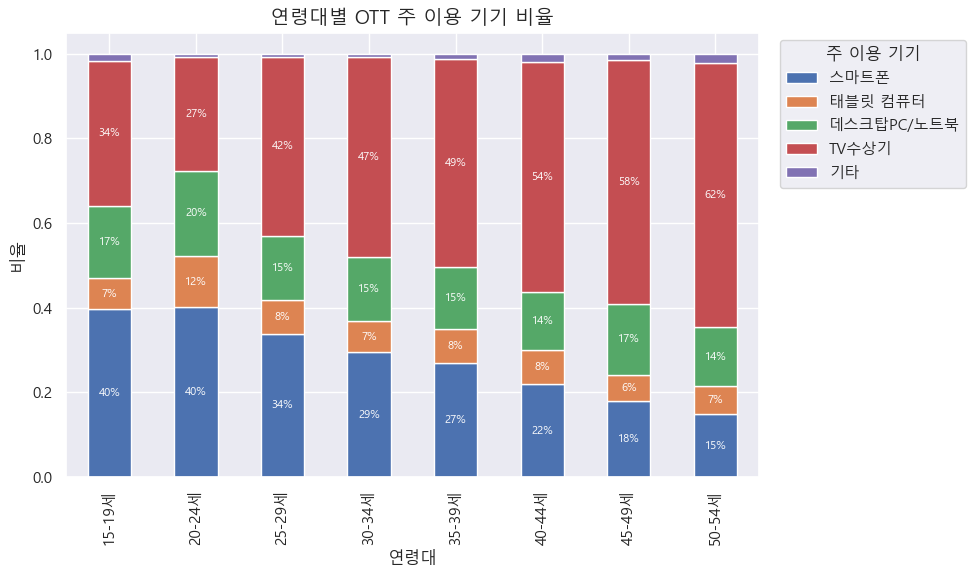

In [25]:
# --------------------------
# 5) 연령대별 기기 비율 시각화 (누적 막대)
# --------------------------
prop = ct.div(ct.sum(axis=1), axis=0)

ax = prop.plot(kind='bar', stacked=True, figsize=(10,6))
ax.set_title('연령대별 OTT 주 이용 기기 비율', fontsize=14)
ax.set_xlabel('연령대')
ax.set_ylabel('비율')
ax.legend(title='주 이용 기기', bbox_to_anchor=(1.02,1), loc='upper left')
for p in ax.patches:
    if p.get_height() > 0.06:  # 너무 작으면 라벨 생략
        ax.text(p.get_x()+p.get_width()/2, p.get_y()+p.get_height()/2,
                f"{p.get_height():.0%}", ha='center', va='center', fontsize=8, color='white')
plt.tight_layout()
plt.show()



In [26]:
# --------------------------
# 6) 가설 확인용: 스마트폰 비율 트렌드 (연령↑ → 스마트폰↓ ?)
# --------------------------
smartphone_rate = (ct['스마트폰'] / ct.sum(axis=1)).reindex(age_order)

print("\n=== 연령대별 스마트폰 이용 비율 ===")
print((smartphone_rate*100).round(1).astype(str) + '%')



=== 연령대별 스마트폰 이용 비율 ===
age
15-19세    39.6%
20-24세    40.1%
25-29세    33.8%
30-34세    29.5%
35-39세    26.9%
40-44세    22.0%
45-49세    17.9%
50-54세    14.8%
그 외        nan%
dtype: object


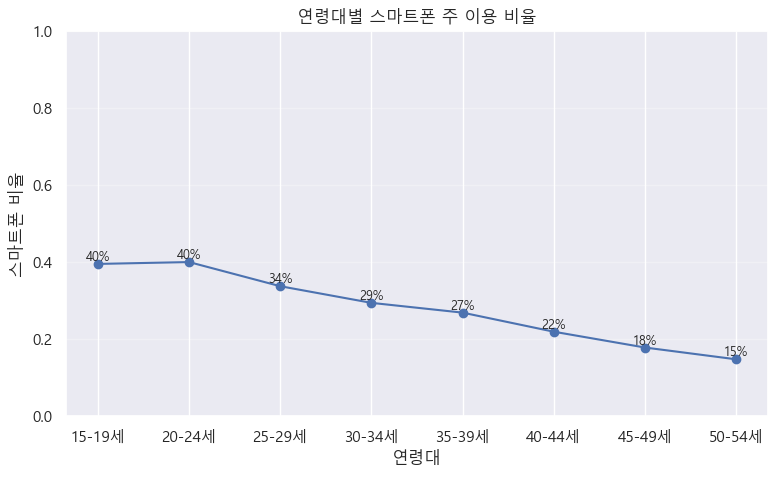

In [27]:
# 꺾은선 그래프
plt.figure(figsize=(8,5))
plt.plot(smartphone_rate.index.astype(str), smartphone_rate.values, marker='o')
plt.title('연령대별 스마트폰 주 이용 비율')
plt.xlabel('연령대')
plt.ylabel('스마트폰 비율')
for x, y in zip(smartphone_rate.index, smartphone_rate.values):
    plt.text(x, y, f"{y:.0%}", ha='center', va='bottom', fontsize=9)
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:
# --------------------------
# 7) 단조 추세 검정(보너스): Spearman 상관 (연령 순서 vs 스마트폰 비율)
#     값 < 0 이고 유의하면 "연령↑일수록 스마트폰↓" 경향
# --------------------------
# 연령 카테고리 → 순서 인덱스(0,1,2,...)
age_idx = pd.Series(range(len(age_order)), index=age_order)
valid = smartphone_rate.dropna()
rho, p_s = spearmanr(age_idx.loc[valid.index].values, valid.values)
print("\n=== Spearman 추세 검정(연령 순서 vs 스마트폰 비율) ===")
print(f"Spearman ρ: {rho:.3f}, p-value: {p_s:.4g}")
if p_s < 0.05:
    print("➡ 유의한 단조 추세 있음 (ρ<0이면 연령↑일수록 스마트폰 비율↓)")
else:
    print("➡ 유의한 단조 추세 없음")

# --------------------------
# 8) 깔끔 표: 연령대별 기기 비중(%) 테이블
# --------------------------
prop_pct = (prop * 100).round(1)
print("\n=== 연령대별 기기 비중(%) ===")
print(prop_pct)


=== Spearman 추세 검정(연령 순서 vs 스마트폰 비율) ===
Spearman ρ: -0.976, p-value: 3.314e-05
➡ 유의한 단조 추세 있음 (ρ<0이면 연령↑일수록 스마트폰 비율↓)

=== 연령대별 기기 비중(%) ===
ott_main_device  스마트폰  태블릿 컴퓨터  데스크탑PC/노트북  TV수상기   기타
age                                                   
15-19세           39.6      7.4        17.1   34.3  1.6
20-24세           40.1     12.1        20.2   26.8  0.8
25-29세           33.8      8.1        15.1   42.3  0.7
30-34세           29.5      7.3        15.3   47.1  0.8
35-39세           26.9      8.1        14.6   49.2  1.1
40-44세           22.0      8.1        13.7   54.4  1.8
45-49세           17.9      6.3        16.8   57.5  1.5
50-54세           14.8      6.7        13.9   62.3  2.3


=== 교차표 (빈도, 인도네시아) ===
ott_main_device  스마트폰  태블릿 컴퓨터  데스크탑PC/노트북  TV수상기  기타
age                                                  
15-19세             75        4          25      8   0
20-24세            267       17          96     56   0
25-29세            203       25          41     41   1
30-34세            178       20          44     74   1
35-39세             80       12          21     28   0
40-44세             54        6          11     23   1
45-49세             23        6          14     20   3
50-54세             13        3           6     12   0

=== 카이제곱 검정 결과 ===
Chi-square: 107.9045
자유도: 28
p-value: 2.55421e-11
➡ 유의미한 연관성 있음

=== 추가 통계 ===
Cramér's V: 0.1336
p-value (0...형식): 0.00000000002554207151


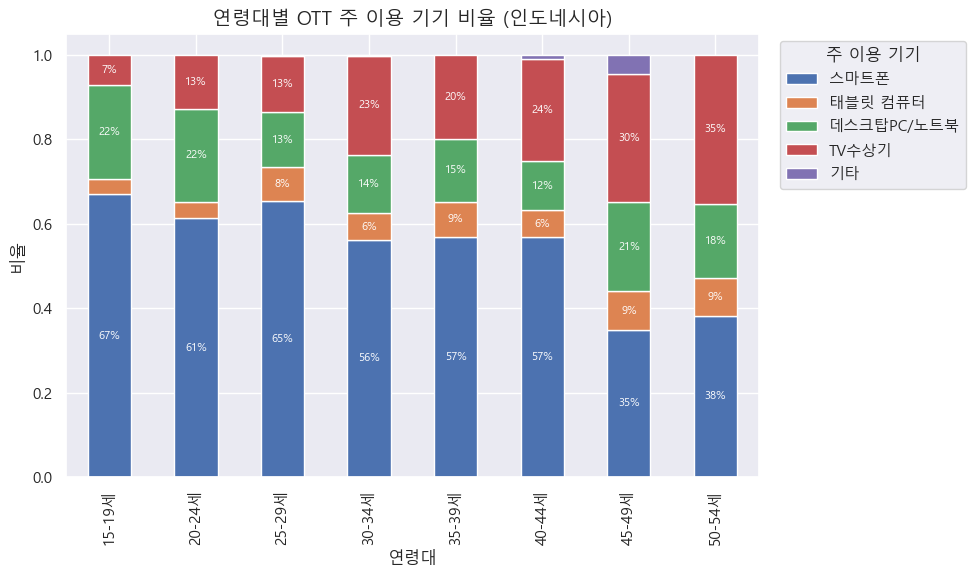

In [31]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

# --------------------------
# 1) 테이블 불러오기 (nation 포함)
# --------------------------
user_df   = pd.read_sql("SELECT user_id, age, nation FROM user", engine)
device_df = pd.read_sql("SELECT user_id, ott_main_device FROM device", engine)

# --------------------------
# 2) 인도네시아만 필터링
# --------------------------
user_df = user_df[user_df['nation'] == '인도네시아']

# --------------------------
# 3) 범주 정렬(라벨 순서 고정)
# --------------------------
age_order = [
    '15-19세','20-24세','25-29세','30-34세',
    '35-39세','40-44세','45-49세','50-54세','그 외'
]
device_order = ['스마트폰','태블릿 컴퓨터','데스크탑PC/노트북','TV수상기','기타']

user_df['age'] = pd.Categorical(user_df['age'], categories=age_order, ordered=True)
device_df['ott_main_device'] = pd.Categorical(device_df['ott_main_device'], categories=device_order, ordered=False)

# --------------------------
# 4) 병합
# --------------------------
df = user_df.merge(device_df, on='user_id', how='inner').dropna(subset=['age','ott_main_device'])

# --------------------------
# 5) 교차표 & 카이제곱
# --------------------------
ct = pd.crosstab(df['age'], df['ott_main_device'])

print("=== 교차표 (빈도, 인도네시아) ===")
print(ct)

chi2, p, dof, expected = chi2_contingency(ct)
print("\n=== 카이제곱 검정 결과 ===")
print(f"Chi-square: {chi2:.4f}")
print(f"자유도: {dof}")
print(f"p-value: {p:.6g}")
print("➡ 유의미한 연관성 있음" if p < 0.05 else "➡ 유의미한 연관성 없음")

# --------------------------
# 6) 크래머 V 계산
# --------------------------
n = ct.to_numpy().sum()  # 전체 표본 수
min_dim = min(ct.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

# --------------------------
# 7) p-value 0... 형식 변환
# --------------------------
def format_small_p(p_value):
    p_value = float(p_value)
    if p_value >= 1e-4:
        return f"{p_value:.4f}"
    else:
        s = f"{p_value:.20f}"
        return s.rstrip('0').rstrip('.')

p_formatted = format_small_p(p)

print("\n=== 추가 통계 ===")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"p-value (0...형식): {p_formatted}")

# --------------------------
# 8) 연령대별 기기 비율 시각화 (누적 막대)
# --------------------------
prop = ct.div(ct.sum(axis=1), axis=0)

ax = prop.plot(kind='bar', stacked=True, figsize=(10,6))
ax.set_title('연령대별 OTT 주 이용 기기 비율 (인도네시아)', fontsize=14)
ax.set_xlabel('연령대')
ax.set_ylabel('비율')
ax.legend(title='주 이용 기기', bbox_to_anchor=(1.02,1), loc='upper left')

for p in ax.patches:
    if p.get_height() > 0.06:
        ax.text(p.get_x() + p.get_width()/2, p.get_y() + p.get_height()/2,
                f"{p.get_height():.0%}", ha='center', va='center', fontsize=8, color='white')

plt.tight_layout()
plt.show()



=== 인도네시아 OTT 주 이용 기기 비율 ===
ott_main_device
스마트폰          59.1%
TV수상기         17.3%
데스크탑PC/노트북    17.1%
태블릿 컴퓨터        6.2%
기타             0.4%
Name: count, dtype: object


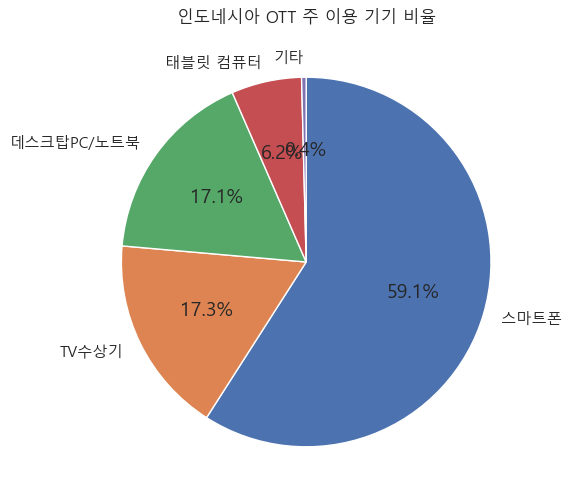

In [32]:
# --------------------------
# 인도네시아 전체 주 이용 기기 비율
# --------------------------
device_counts = df['ott_main_device'].value_counts(dropna=False)
device_ratio = device_counts / device_counts.sum()

print("\n=== 인도네시아 OTT 주 이용 기기 비율 ===")
print(device_ratio.apply(lambda x: f"{x:.1%}"))

# 시각화
plt.figure(figsize=(6,6))
plt.pie(device_ratio, labels=device_ratio.index, autopct="%.1f%%", startangle=90, counterclock=False)
plt.title("인도네시아 OTT 주 이용 기기 비율")
plt.show()

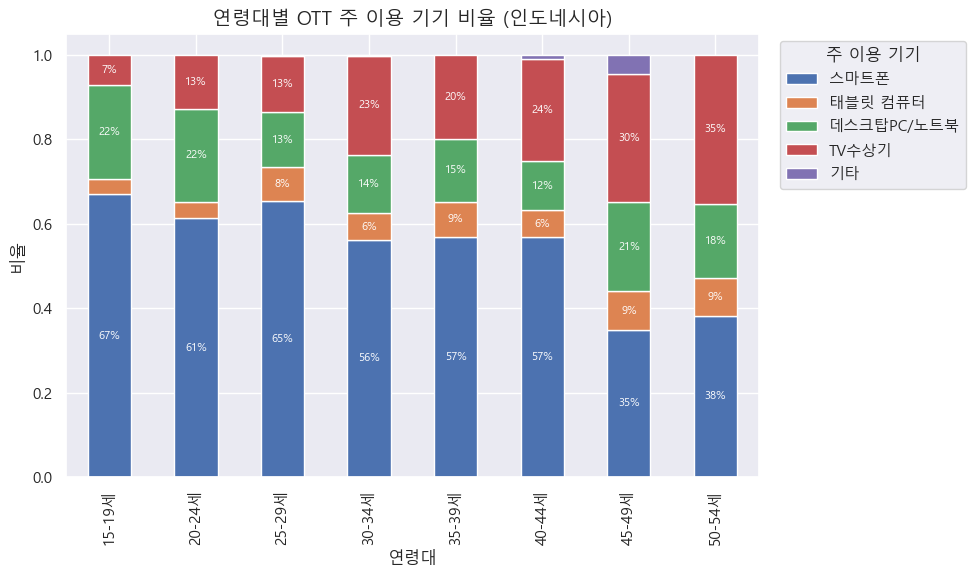

In [33]:
prop = ct.div(ct.sum(axis=1), axis=0)

ax = prop.plot(kind='bar', stacked=True, figsize=(10,6))
ax.set_title('연령대별 OTT 주 이용 기기 비율 (인도네시아)', fontsize=14)
ax.set_xlabel('연령대')
ax.set_ylabel('비율')
ax.legend(title='주 이용 기기', bbox_to_anchor=(1.02,1), loc='upper left')

for p in ax.patches:
    if p.get_height() > 0.06:
        ax.text(p.get_x() + p.get_width()/2, p.get_y() + p.get_height()/2,
                f"{p.get_height():.0%}", ha='center', va='center', fontsize=8, color='white')

plt.tight_layout()
plt.show()


=== 전체 OTT 주 이용 기기 비율 ===
ott_main_device
TV수상기         45.4%
스마트폰          29.1%
데스크탑PC/노트북    16.0%
태블릿 컴퓨터        8.3%
기타             1.2%
Name: count, dtype: object


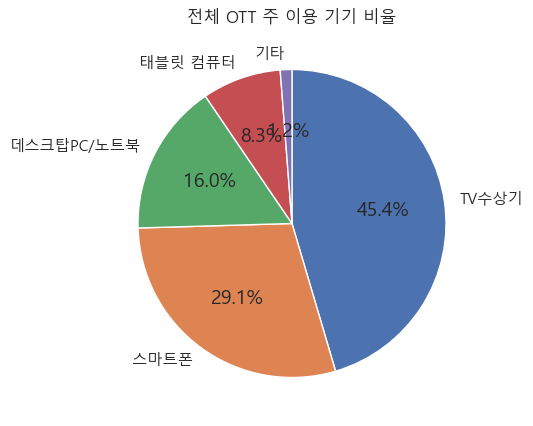

In [39]:
# --------------------------
# 1) 테이블 불러오기 (nation 포함)
# --------------------------
user_df   = pd.read_sql("SELECT user_id, age, nation FROM user", engine)
device_df = pd.read_sql("SELECT user_id, ott_main_device FROM device", engine)

# 범주 정렬
age_order = [
    '15-19세','20-24세','25-29세','30-34세','35-39세','40-44세','45-49세','50-54세','그 외'
]
device_order = ['스마트폰','태블릿 컴퓨터','데스크탑PC/노트북','TV수상기','기타']

user_df['age'] = pd.Categorical(user_df['age'], categories=age_order, ordered=True)
device_df['ott_main_device'] = pd.Categorical(device_df['ott_main_device'], categories=device_order, ordered=False)

# --------------------------
# 2) 병합
# --------------------------
df = user_df.merge(device_df, on='user_id', how='inner').dropna(subset=['age','ott_main_device'])

# --------------------------
# 3) 특정 국가별 주 이용 기기 비율 함수
# --------------------------
def plot_device_ratio(data, nation_name):
    device_counts = data['ott_main_device'].value_counts(dropna=False)
    device_ratio = device_counts / device_counts.sum()

    print(f"\n=== {nation_name} OTT 주 이용 기기 비율 ===")
    print(device_ratio.apply(lambda x: f"{x:.1%}"))

    # 시각화
    plt.figure(figsize=(5,5))
    plt.pie(device_ratio, labels=device_ratio.index, autopct="%.1f%%", startangle=90, counterclock=False)
    plt.title(f"{nation_name} OTT 주 이용 기기 비율")
    plt.show()

# --------------------------
# 4) 전체 / 인도네시아 / 대만 / 미국
# --------------------------
plot_device_ratio(df, "전체")



=== 인도네시아 OTT 주 이용 기기 비율 ===
ott_main_device
스마트폰          59.1%
TV수상기         17.3%
데스크탑PC/노트북    17.1%
태블릿 컴퓨터        6.2%
기타             0.4%
Name: count, dtype: object


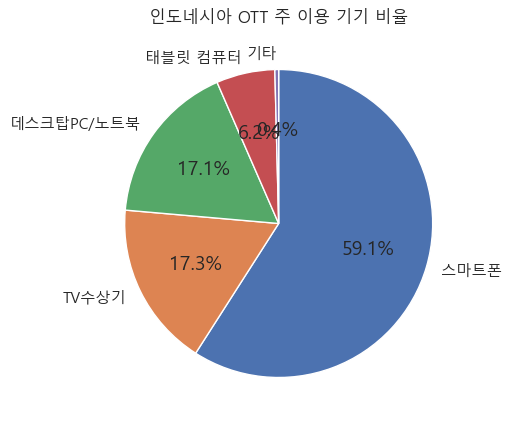


=== 대만 OTT 주 이용 기기 비율 ===
ott_main_device
데스크탑PC/노트북    32.2%
스마트폰          31.2%
TV수상기         24.3%
태블릿 컴퓨터       11.5%
기타             0.8%
Name: count, dtype: object


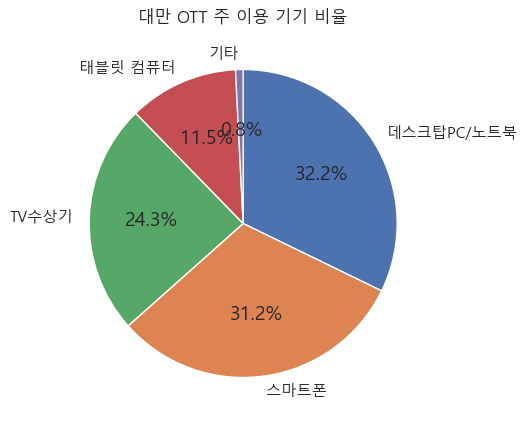


=== 미국 OTT 주 이용 기기 비율 ===
ott_main_device
TV수상기         50.7%
스마트폰          28.6%
데스크탑PC/노트북    11.4%
태블릿 컴퓨터        6.6%
기타             2.8%
Name: count, dtype: object


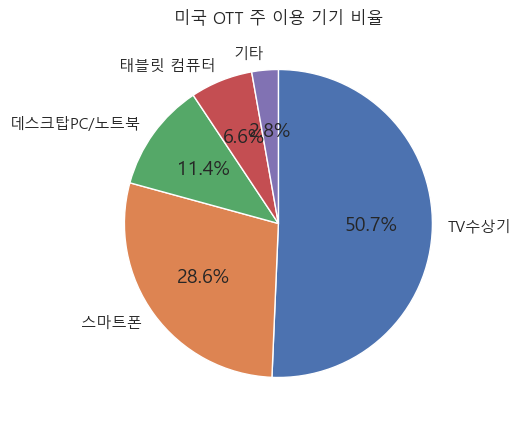

In [40]:
plot_device_ratio(df[df['nation'] == "인도네시아"], "인도네시아")
plot_device_ratio(df[df['nation'] == "대만"], "대만")
plot_device_ratio(df[df['nation'] == "미국"], "미국")